In [18]:
import numpy as np
import pandas as pd
import optuna
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

# Загрузим данные

- Данные упорядочены по времени
- Задача - предсказать `target`
- Фичи - `feature_i`
- Трейн, валидация и тест уже определены (см. колонку `sample_part`)

In [19]:
df = pd.read_parquet('df.parquet.gzip')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 22620 to 310653
Columns: 235 entries, date to sample_part
dtypes: category(2), datetime64[ms](1), datetime64[ns](2), float64(220), int64(9), object(1)
memory usage: 893.6+ MB


In [20]:
df.head()

,date,month,quarter,feature_217,feature_66,feature_9,feature_193,feature_15,feature_199,feature_25,...,feature_20,feature_188,feature_71,feature_106,feature_14,feature_92,feature_179,feature_102,target,sample_part
22620,2021-01-01,2021-01-01,2021-01-01,1.180855,0.483118,13.976791,1.135021,43.271792,-46.888875,97.558366,...,23.745198,-32.001093,85.489903,1.454045,-195.725786,3.719083,1,-28.813537,0.0,train
478621,2021-01-01,2021-01-01,2021-01-01,3.427814,0.886778,27.158209,-0.378728,80.087863,-67.242703,105.803406,...,22.902111,-37.436243,71.735619,1.657242,-176.250404,3.277817,1,-45.987721,1.0,train
372254,2021-01-01,2021-01-01,2021-01-01,-38.555018,1.227175,19.893873,0.498787,98.464365,-67.402522,81.858076,...,21.848414,-51.872841,65.363236,1.626874,-178.116798,2.028950,0,-31.074122,1.0,train
2596,2021-01-01,2021-01-01,2021-01-01,-14.666558,0.753129,18.203010,-1.200014,117.331340,-25.557745,90.277266,...,26.134586,-49.703003,65.013659,1.170023,-192.232264,2.218177,1,-36.703897,0.0,train
216892,2021-01-01,2021-01-01,2021-01-01,6.734990,1.129100,11.245920,-0.108955,61.205722,-78.397406,82.637472,...,24.201039,-41.070219,69.986127,1.630795,-200.155528,3.055104,1,-44.672299,1.0,train


In [21]:
TARGET = 'target'
N_FEATURES = 230
features = [f'feature_{i}' for i in range(N_FEATURES)]

# Первичный отбор признаков... (1 балл)

**Задание:** Сначала отсеем совсем уж мусорные признаки.

Воспользовавшись вашим кодом для вычисления `IV` из прошлой домашки, для всех **числовых** фичей вычислите `IV` на 20 бакетах. Отсейте признаки с `IV < 0.005`.

**Hint:** паркет не всегда сохраняет `dtype` колонки. Чтобы проверить признаки на "реальный" тип данных, лучше на всякий случай посмотреть на `nunique` 

In [22]:
# your code here
from typing import Union
from scipy.special import logit

def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на 
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets
def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

def calc_IV(
        values : Union[np.ndarray, pd.Series],
        target : Union[np.ndarray, pd.Series],
        n_buckets : int
    ) -> float:
    buckets = calc_buckets(values, n_buckets)
    
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # всё ещё простите за это...

    return IV

In [23]:
# В отдельную ячейку, потому что долго.
num_df_columns = [x for x in df.select_dtypes(include=['float64', 'int64']).columns if df[x].nunique() > 50  ]
target_train = df[TARGET][df['sample_part'] == 'train']
iv_arr = {}

In [24]:
for x in num_df_columns:
    val_raw = df[x][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train, 20)
    iv_arr[x] = iv 

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\series.py:1031: RuntimeWarning: invalid value encountered in cast
  arr = np.asarray(values, dtype=dtype)


In [25]:
iv_selected_features = [f for f, iv in iv_arr.items() if iv >= 0.005]
print(len(iv_selected_features), iv_selected_features)

57 ['feature_9', 'feature_15', 'feature_154', 'feature_218', 'feature_96', 'feature_223', 'feature_30', 'feature_225', 'feature_162', 'feature_167', 'feature_109', 'feature_124', 'feature_79', 'feature_213', 'feature_117', 'feature_38', 'feature_24', 'feature_75', 'feature_5', 'feature_56', 'feature_114', 'feature_139', 'feature_65', 'feature_142', 'feature_12', 'feature_35', 'feature_227', 'feature_115', 'feature_155', 'feature_132', 'feature_76', 'feature_97', 'feature_140', 'feature_135', 'feature_2', 'feature_46', 'feature_100', 'feature_111', 'feature_138', 'feature_164', 'feature_98', 'feature_36', 'feature_183', 'feature_27', 'feature_156', 'feature_4', 'feature_32', 'feature_206', 'feature_172', 'feature_70', 'feature_44', 'feature_23', 'feature_170', 'feature_39', 'feature_216', 'feature_94', 'feature_43']


**Вопрос**: Почему некорректно сравнивать `IV` у категориальных и числовых фичей?

Вычислите IV для категориальных фичей на `n` бакетах, где `n = min(число категорий фичи, 20)`. Возможно, придётся перекодировать некоторые фичи (*только не OneHot-ом!*)

*Опционально*: примените также и к категориальным фичам предварительный отбор по `IV` с менее строгим порогом

In [26]:
# your code here
cat_df_columns = [x for x in df.select_dtypes(include=['category', 'int64']).columns if df[x].nunique() <= 50 ]
cat_df_columns

['feature_147',
 'feature_144',
 'feature_168',
 'feature_165',
 'feature_31',
 'feature_0',
 'feature_209',
 'feature_222',
 'feature_37',
 'feature_157',
 'feature_179']

In [27]:
iv_selected_cat_features = {}
for y in cat_df_columns:
    val_raw = df[y][df['sample_part'] == 'train']
    val = np.asarray(val_raw)
    iv = calc_IV(val, target_train,  min(20, len(np.unique(val)) ))
    iv_selected_cat_features[y] = iv 

iv_selected_cat_features = [f for f, iv in iv_selected_cat_features.items() if iv >= 0.001]
len(iv_selected_cat_features), iv_selected_cat_features

(6,
 ['feature_147',
  'feature_144',
  'feature_168',
  'feature_165',
  'feature_31',
  'feature_209'])

**Ответ:** сравнивать IV у категориальных и числовых фичей некорректно, потому что мы теряем какую-то часть информации о непрерывных фичах из-за биннинга, потому что мы для корректного подсчёта IV мы должны относиться к ней, как к дискретной случайной величине, а тогда мы можем очень плохо поделить на бакеты, чтобы получить дискретность, и поэтому получить низкий IV, хотя проблема была не в самой фиче, а в разбиении на бакеты, категориальные фичи же в свою очередь от такой проблемы не страдают, потому что уже дискретны, поэтому для них IV не занижается.

# Бустинг

Используйте код для подбора гиперпараметров и обучения бустинга из предыдущей домашки

In [28]:
# В переменную features_optuna положите список признаков с предыдущего шага
features_optuna = iv_selected_features + iv_selected_cat_features
len(features_optuna)

63

In [29]:
import lightgbm as lgb

In [37]:
import optuna

train_data_df = df[df['sample_part'] == 'train']
valid_data_df = df[df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[features_optuna], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[features_optuna], label=valid_data_df[TARGET])

X_test = valid_data_df[features_optuna]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'n_jobs' : -1,
        'random_state': 52,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 12:25:43,715] A new study created in memory with name: no-name-de463d5a-8d83-49de-924e-d623279bbe7d


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[99]	valid_0's auc: 0.736161


[I 2026-08-19 12:25:50,113] Trial 0 finished with value: 0.7361612064108791 and parameters: {'num_leaves': 154, 'learning_rate': 0.10563694915167389, 'feature_fraction': 0.5}. Best is trial 0 with value: 0.7361612064108791.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.715902


[I 2026-08-19 12:26:05,043] Trial 1 finished with value: 0.7159015167557066 and parameters: {'num_leaves': 188, 'learning_rate': 0.021388113771873784, 'feature_fraction': 0.9}. Best is trial 0 with value: 0.7361612064108791.


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.697135


[I 2026-08-19 12:30:25,851] Trial 48 finished with value: 0.6971352102962604 and parameters: {'num_leaves': 174, 'learning_rate': 0.0030215391167481087, 'feature_fraction': 0.5}. Best is trial 41 with value: 0.7393039091792133.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.735174


[I 2026-08-19 12:30:29,720] Trial 49 finished with value: 0.7351736779990287 and parameters: {'num_leaves': 85, 'learning_rate': 0.12450051895625913, 'feature_fraction': 0.6}. Best is trial 41 with value: 0.7393039091792133.


Best params: {'num_leaves': 192, 'learning_rate': 0.08666957166696355, 'feature_fraction': 0.6}
Best AUC: 0.7393039091792133


## Важность признаков (1 балл)

**Задание:** Постойте гистограмму важности признаков по `split` и `gain` для бустинга из предыдущего пункта.

In [38]:
#####
# <your code here>
#####
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_lgb = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_lgb.predict(df[df['sample_part'] == 'test'][features_optuna])))

0.7239271888753497


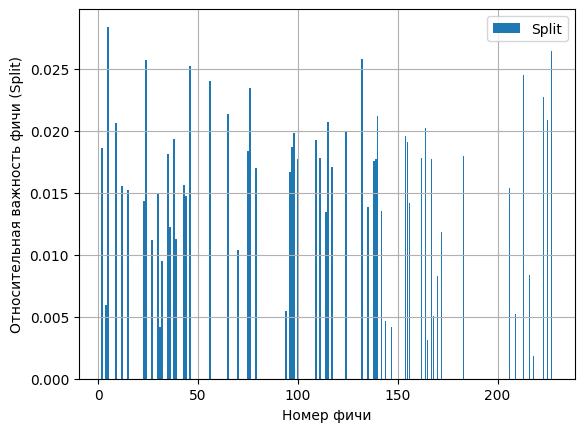

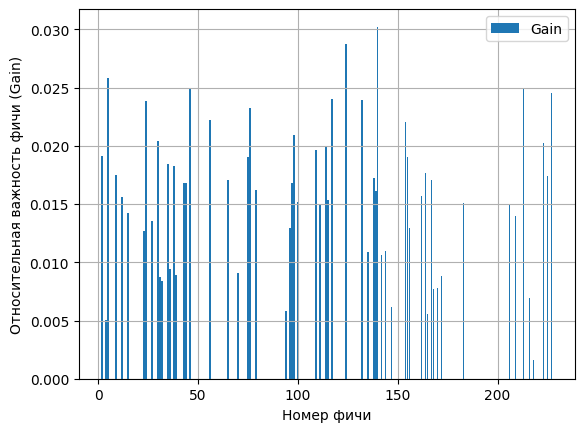

In [45]:
space = [int(feature[-4:].split('_')[1]) for feature in train_data_df[features_optuna].columns]
split_importance = model_lgb.feature_importance(importance_type='split')
plt.bar(space, split_importance / sum(split_importance), label = 'Split')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Split)")
plt.grid()
plt.legend()
plt.show()

gain_importance = model_lgb.feature_importance(importance_type='gain')
plt.bar(space, gain_importance / sum(gain_importance), label = 'Gain')
plt.xlabel("Номер фичи")
plt.ylabel("Относительная важность фичи (Gain)")
plt.grid()
plt.legend()
plt.show()

**Вопрос:** Какие выводы можно сделать из полученных графиков?

И по gain, и по split фичи имеют примерно одинаковую важность, отличаются пики, но визуально картина примерно одинаковая: в районе 220 есть признак, у которого наименьшая важность по обоим методам среди других признаков, наибольшую важность по гейну имеет признак в районе 140, когда по сплиту наиболее важный признак находится в районе 10.

# Логрег

## plot_metric_time (1 балл)

**Задание:** Реализуйте функцию plot_metric_time, которая будет принимать на вход четыре аргумента, а именно: 
- массив значений фичи, 
- массив значений таргета,
- массив времени (аггрегированного по месяцам или кварталам, то есть `month` или `quarter` в вашей задаче, по дням рисовать не надо),
- метрику, которую необходимо отрисовать (нужно реализовать функцию для двух метрик: `IV` и `roc_auc`)
- число бакетов для вычисления `IV`, если выбрана эта метрика

Можете добваить какие-то ещё аргументы, если вам нужно

Если в фиче есть пропуски, функция должна убирать строки с пропусками из рассмотрения

**Hint**: можно, конечно, реализовать эту функцию через цикл, а можно попробовать разобраться и реализовать её через пандасовские `groupby` -> `apply`, это изящнее и быстрее

In [40]:
import plotly.graph_objects as go

In [41]:
def plot_metric_time(
        values: pd.Series,
        target: pd.Series,
        time: pd.Series,
        metric: str = 'IV',
        n_buckets_for_IV: int = 15,
        date_or_quarter : str = 'date',
        show_or_return : str = 'show'
) -> go.Figure:
    
    if date_or_quarter not in ['date', 'quarter']:
        raise NotImplementedError("Pass either date or quarter")

    if show_or_return not in ['show', 'return']:
        raise NotImplementedError("Pass either show or return")
    
    feature = values.name
    time.name = date_or_quarter
    values = pd.concat([values, target, time], axis = 1)
    values = values.dropna()
    proper_values = values 

    if metric == 'IV':
        res = proper_values.groupby(by = date_or_quarter).apply(lambda x: calc_IV(x[feature], x['target'], n_buckets_for_IV), include_groups = False)
    elif metric == 'roc_auc':
       res = proper_values.groupby(by = date_or_quarter).apply(lambda x: roc_auc_score(x['target'], x[feature]), include_groups = False)
    else:
        raise NotImplementedError("only 'IV' and 'roc_auc' metrics are implemented")

    # your code here

    plot_title = f'{feature}, {metric} in time'
    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x= res.index, # месяцы или кварталы, your code here
            y= res.values, # аггрегированное значение метрики, your code here
            mode='markers+lines',
            name=feature# имя фичи, your code here
            ))
    fig.update_layout(
            title_text=plot_title,
            yaxis=dict(title=metric),
            width=1000,
            height=450,
            xaxis=dict(
                domain=[0, .95],
                showgrid=True,
                tickvals=res.index  # месяцы или кварталы, your code here
                ),
            margin=dict(l=30, r=30, b=30, t=50),
            )
    if show_or_return == 'show':
        fig.show()
    else:
        return fig

In [42]:
# примерно так это должно будет выглядеть
plot_metric_time(df['feature_52'], df['target'], df['quarter']) 

**Задание:** Возьмите **топ-15** фичей получившегося бустинга по важности по `gain`. Отрисуйте для них графики стабильности по `IV` во времени и удалите из рассмотрения те признаки, качество которых деградирует

**NB!** Обращайте внимание на масштаб оси *y!* Иногда признак стабильнее, чем кажется)

Если вам это мешает, можете поменять ось *y*, чтобы она начиналась от нуля в прошлом задании.

Отрисовывать будем по трейну, потому что, кажется, неправильно, когда мы отбираем на всём датасете, потому что мы получаем информацию из теста и на её основе делаем преобразование, а это уже пахнет утечкой данных, поэтому ограничимся только анализом на трейне, но преобразовывать будем весь признак.

In [46]:
# your code here
top_15_idxs = np.argsort(gain_importance)[-15:]
top_15_features = [features_optuna[idx] for idx in top_15_idxs] [::-1]

In [47]:
for feature in top_15_features: 
    plot_metric_time(train_data_df[feature], target_train, train_data_df['quarter'])

**Список деградирующих фичей:**

132, 223.
Так как остальные признаки либо колеблются, либо держутся примерно в одних и тех же значениях, либо показывают +- стабильный рост, только эти фичи показывает какую-то деградацию.

На этом моменте предлагаю сделать новый маленький датафрейм, чтобы не "портить" исходный

И проводить все манипуляции с фичами на нём

In [214]:
top15features_stable = [feature for feature in top_15_features if feature not in ['feature_132', 'feature_223']]

df_for_logreg = df[top15features_stable + ['date', 'month', 'quarter', 'target', 'sample_part']]
top15features_stable

['feature_140',
 'feature_124',
 'feature_5',
 'feature_46',
 'feature_213',
 'feature_227',
 'feature_117',
 'feature_24',
 'feature_76',
 'feature_56',
 'feature_154',
 'feature_98',
 'feature_30']

## Предобработка признаков (3 балла)

**Задание:** Используя функицю woe_line из ДЗ по логрегу, проверьте **числовые** фичи из полученного списка фичей на линейность по WoE на трейн-выборке (если в фиче есть пропуски - дропаем их при отрисовке)

Если фичи нелинейные, **линеаризуйте их**.

Преобразования, которые можно/стоит пробовать:
- клипы (`np.clip`) - зачастую их достаточно
- корень
- квадрат
- логарифм

Если нужно, можно прибавлять к фиче константу или менять её знак

При желании можно "распилить фичу на две половины" (если она немонотонна) и линеаризовать их по отдельности

Однако слишком упираться в линеаризацию фичей не нужно. Если фича ну совсем никак не линеаризуется, в крайнем случае можно её дропнуть или оставить как есть.

При отрисовке можно ограничиться 15-20 бактеами

In [215]:
# your code here
from typing import Tuple
from sklearn.linear_model import LogisticRegression
import scipy.stats as sps

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"] - buckets_info["woe"],
                arrayminus=buckets_info["woe"] - buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature

    model = LogisticRegression()
    model = model.fit(values.reshape(-1, 1), target) # reshape, иначе ругается sklearn

    # .predict_proba возвращает матрицу (n_samples, n_classes)
    # простыми словами он возращает матрицу вида:
    # (P(y = 0 | x_1), P(y = 1 | x_1))
    # (...)
    # (P(y = 0 | x_n), P(y = 1 | x_n))
    # Так как в логреге мы интересуемся P(y = 1 | X), 
    # то и берём мы только второй столбец.

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float) -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate, badrate_lower, badrate_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
        badrate[bucket] = target[buckets == bucket].mean()
        add_val = sps.norm.ppf(1 - 0.05 / 2, loc = 0, scale = 1) * ((badrate[bucket]) * (1 - badrate[bucket]) / len(target[buckets == bucket]))**0.5
        badrate_lower[bucket] =  badrate[bucket] - add_val
        badrate_upper[bucket] =  badrate[bucket] + add_val

    # переходим от бэдрейта к woe
    woe, woe_lower, woe_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
            woe[bucket] = woe_transform(badrate=badrate[bucket], offset=offset)
            woe_lower[bucket] = woe_transform(badrate = badrate_lower[bucket], offset = offset)
            woe_upper[bucket] = woe_transform(badrate = badrate_upper[bucket], offset=offset)
    return woe, woe_lower, woe_upper

def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""

    mean_feature = np.array([values[buckets == i].mean() for i in sorted(set(buckets))])
    offset = logit(target.mean())
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : calc_line(values, target, mean_feature, offset),
        "woe"          : woe,
        "woe_lower"    : woe_lower,
        "woe_upper"    : woe_upper
    }

    return buckets_info

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # простите за это..

    # Взвешенный R^2 
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете

    # Будем считать как квадрат корреляции, потому что здесь -
    # https://en.wikipedia.org/wiki/Coefficient_of_determination
    # - так написано, а кто я такой, чтобы не верить?

    X_arr = []
    w_arr = []
    woe_buck, _, _ = woe_ci(target, buckets, offset)
    woe_buck = np.asarray(woe_buck)
    
    for i in sorted(set(buckets)):
        bucket = target[buckets == i]
        X_arr.append(values[buckets == i].mean())
        w_arr.append(len(bucket))

    w_arr = np.array(w_arr)
    X_arr = np.array(X_arr)

    w_s = w_arr.sum()
    X_w_mean = np.sum([w_arr[i] * X_arr[i] for i in range(len(set(buckets)))]) / w_s
    Y_w_mean = np.sum([w_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s

    X_arr = X_arr - X_w_mean
    woe_buck = woe_buck - Y_w_mean

    cov = np.sum([w_arr[i] * X_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s
    var_x = np.sum([w_arr[i] * X_arr[i] ** 2 for i in range(len(set(buckets)))]) / w_s
    var_y = np.sum([w_arr[i] * woe_buck[i] ** 2 for i in range(len(set(buckets)))]) / w_s

    R_sqr = cov ** 2 / (var_x * var_y)

    plot_title = (        
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

In [216]:
for x in top15features_stable:
    print(train_data_df[x].dtype, x)

float64 feature_140
float64 feature_124
float64 feature_5
float64 feature_46
float64 feature_213
float64 feature_227
float64 feature_117
float64 feature_24
float64 feature_76
float64 feature_56
float64 feature_154
float64 feature_98
float64 feature_30


Видимо придётся проверять все..)

In [217]:
for x in top15features_stable:
    val = train_data_df[x].dropna()
    print(x)
    woe_line(np.asarray(val), np.asarray(target_train[val.index]), 15).show()

feature_140


feature_124


feature_5


feature_46


feature_213


...

feature_76


feature_56


feature_154


feature_98


feature_30


Фичи, которые не надо линеаризовать:

117, 24, 98 - уже лучше, чем ничего, итого под линеаризацию попадут 10 фичей.

In [218]:
lin_cand_features = [feature for feature in top15features_stable if feature not in ['feature_117', 'feature_24', 'feature_98']]
print(len(lin_cand_features), df_for_logreg.head())
logreg_train = df_for_logreg[df_for_logreg['sample_part'] == 'train']
logreg_test = df_for_logreg[df_for_logreg['sample_part'] == 'test']
logreg_train_target = logreg_train['target']
logreg_test_target = logreg_test['target']

10         feature_140  feature_124   feature_5  feature_46  feature_213  \
22620          15.0   -61.495238 -215.945717  115.319640     7.458468   
478621         28.0   -28.477404 -170.713568  172.981221    10.884534   
372254         10.0          NaN -154.503339 -119.580242    17.206131   
2596           22.0   -42.117574 -131.553444   85.009499    18.618423   
216892         50.0   -48.599477 -162.092621   43.108790     8.274292   

        feature_227  feature_117  feature_24  feature_76  feature_56  \
22620   -173.334454   -17.226707   -7.179830   24.511627 -258.724816   
478621  -479.616136    -8.564242  -23.797875 -131.928627  -75.131292   
372254  -222.993621   -10.249472  -22.976857 -130.156221 -270.127459   
2596     312.396421   -13.114987  -14.087877   20.596559 -463.492274   
216892  -201.997489    -7.378194  -17.195954  178.124940  327.178077   

        feature_154  feature_98  feature_30       date      month    quarter  \
22620      0.354745   15.141825    0.036732 2

**Линеаризация.**

1)

In [219]:
val = logreg_train[lin_cand_features[0]].dropna()
print(lin_cand_features[0])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_140


Похоже на ветвь параболы, попробуем квадрат, но накинем на него ещё клиппинг сверху, чтобы точно попасть в нужные значения. Помним, что такой специальный квадрат особо не перемешивает информацию, особенно в совокупности с тем, что средние всех бинов у нас строго положительны.

In [220]:
print("Train:")
val = logreg_train[lin_cand_features[0]].dropna()
val = (np.sign(val) * val ** 2).clip(lower = 400)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[0]].dropna()
val = (np.sign(val) * val ** 2).clip(lower = 400)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Информативность фичи по IV не упала, но видно, что местами значения стали более шумными, особенно этот гигант между 2000 и 2500, скорее всего в этот бин просто попадает мало значений, но так как метрики вполне приемлемые, нас это устраивает. Переобучения тут тоже нет, на тесте $R^2$ просел, но IV повыше.

In [221]:
df_for_logreg.loc[:, lin_cand_features[0]] = (np.sign(df_for_logreg[lin_cand_features[0]]) * (df_for_logreg[lin_cand_features[0]])**2).clip(lower = 400)

In [222]:
val = df_for_logreg[lin_cand_features[0]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

2) 

In [223]:
val = logreg_train[lin_cand_features[1]].dropna()
print(lin_cand_features[1])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_124


Клипы здесь плохо себя показали: либо мы клипуем слишком сильно, из-за чего IV падает, а шум возрастает, либо мы ничего от этого не получаем, кроме ухудшения всех метрик. Возможно это потому, что распределение у фичи такое, что всё полезная информация находится в хвостах, которые мы клипами отсекаем, оставляя только шум. Поэтому попробуем что-то покруче, например, $sign(x) x^2$, потому что график похож на какую-то ветвь параболы, причём во всех бинах среднее получилось строго отрицательным, но мы на всякий случай всё равно сохраним знак, чтобы сильно не перемешивать информацию.

In [224]:
print("Train:")
val = logreg_train[lin_cand_features[1]].dropna()
val = np.sign(val) * val ** 2
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[1]].dropna()
val = np.sign(val) * val ** 2
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Джекпот! Информативность по IV не потеряли, roc-auc остался тем же, при этом по $R^2$ мы стали линейны! Квадрат здесь ничего не портит, так как во всех бинах среднее были отрицательными, поэтому, так как мы сохранили знак, то ничего критичного это отображение с нашими данными не сделала, сильно информацию мы не перемешали. Причём на тесте метрики даже лучше, так что едва ли тут можно судить о каком-то переобучении с таким отображением. 

In [225]:
df_for_logreg.loc[:, lin_cand_features[1]] = np.sign(df_for_logreg[lin_cand_features[1]]) * (df_for_logreg[lin_cand_features[1]])**2

In [226]:
val = df_for_logreg[lin_cand_features[1]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

3)

In [227]:
val = logreg_train[lin_cand_features[2]].dropna()
print(lin_cand_features[2])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_5


Тут попробуем что-то получить при помощи логарифма с правильным знаком и клипинга, в конце накинем косметический минус, чтобы сделать всё обратно отрицательным.

In [228]:
print("Train:")
val = logreg_train[lin_cand_features[2]].dropna()
val = -np.log(np.abs(val)).clip(upper = 5.1)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[2]].dropna()
val = -np.log(np.abs(val)).clip(upper = 5.1)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Конечно, очень жаль, что у нас не получилось прям совсем крутых метрик на тесте, но это тоже неплохо, мы хотя бы не переобучились.

In [229]:
df_for_logreg.loc[:, lin_cand_features[2]] = -np.log(np.abs(df_for_logreg[lin_cand_features[2]])).clip(upper = 5.1)

In [230]:
val = df_for_logreg[lin_cand_features[2]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

4)

In [231]:
val = logreg_train[lin_cand_features[3]].dropna()
print(lin_cand_features[3])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_46


Похоже на какую-то повёрнутую параболу, поэтому попробуем квадрат вместе с клипом.

In [232]:
print("Train:")
val = logreg_train[lin_cand_features[3]].dropna()
val = (val ** 2).clip(upper = 125_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[3]].dropna()
val = (val ** 2).clip(upper = 125_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Мы хороошо линеаризовали фичу, но вместе с этими потеряли в информативности самой фичи, так как IV упал с 0.015 до 0.01, но так как это всё ещё больше нашей мусорной границы в 0.005, то нас это устраивает.

In [233]:
df_for_logreg.loc[:, lin_cand_features[3]] = (df_for_logreg[lin_cand_features[3]] ** 2).clip(upper = 125_000)

In [234]:
val = df_for_logreg[lin_cand_features[3]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

5) 

In [235]:
val = logreg_train[lin_cand_features[4]].dropna()
print(lin_cand_features[4])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_213


Казалось бы, что очень похоже на то, что у нас уже было, но никакие из выше указанных функций не подходят, кроме $\frac{1}{x}$, поэтому возьмём её вместе с клипом.

In [236]:
print("Train:")
val = logreg_train[lin_cand_features[4]].dropna()
val = (1 / val).clip(lower = 0.08, upper = 0.25)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[4]].dropna()
val = (1 / val).clip(lower = 0.08, upper = 0.25)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Опять же, не прям идеально, но уже неплохо.


In [237]:
df_for_logreg.loc[:, lin_cand_features[4]] = (1 / df_for_logreg[lin_cand_features[4]]).clip(lower = 0.08, upper = 0.25)

In [238]:
val = df_for_logreg[lin_cand_features[4]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

6)

In [239]:
val = logreg_train[lin_cand_features[5]].dropna()
print(lin_cand_features[5])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_227


Наш любимый тип: перевернутая парабола, поэтому и смотреть мы будем квадрат с клипом.

In [240]:
print("Train:")
val = logreg_train[lin_cand_features[5]].dropna()
val = (val ** 2).clip(upper = 370_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[5]].dropna()
val = (val ** 2).clip(upper = 370_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [241]:
df_for_logreg.loc[:, lin_cand_features[5]] = (df_for_logreg[lin_cand_features[5]] ** 2).clip(upper = 370_000)

In [242]:
val = df_for_logreg[lin_cand_features[5]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

7) 

In [243]:
val = logreg_train[lin_cand_features[6]].dropna()
print(lin_cand_features[6])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_76


хммм что же это может быть.... настолько явной параболы здесь ещё не встречалось.

In [244]:
print("Train:")
val = logreg_train[lin_cand_features[6]].dropna()
val = val ** 2
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[6]].dropna()
val = val ** 2
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [245]:
df_for_logreg.loc[:, lin_cand_features[6]] = df_for_logreg[lin_cand_features[6]] ** 2

In [246]:
val = df_for_logreg[lin_cand_features[6]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

8) 

In [247]:
val = logreg_train[lin_cand_features[7]].dropna()
print(lin_cand_features[7])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_56


Аналогично прошлой фиче похожа на какую-то переверную параболу, уже знаем, что с такой делать.

In [248]:
print("Train:")
val = logreg_train[lin_cand_features[7]].dropna()
val = (val ** 2).clip(upper = 240_000)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[7]].dropna()
val = (val ** 2).clip(upper = 240_000)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [249]:
df_for_logreg.loc[:, lin_cand_features[7]] = (df_for_logreg[lin_cand_features[7]] ** 2).clip(upper = 240_000)

In [250]:
val = df_for_logreg[lin_cand_features[7]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

9)

In [251]:
val = logreg_train[lin_cand_features[8]].dropna()
print(lin_cand_features[8])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_154


Здесь совсем немного не хватает до идеала, нужно просто сделать небольшой клип.

In [252]:
print("Train:")
val = logreg_train[lin_cand_features[8]].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[8]].dropna()
val =  val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Ого, как оказалось, на тесте наша фича просто умирает, но проблема в том, что она и без преобразования сильно отличается от трейна, поэтому даже если мы оставим трейн без изменений, то на тесте всё равно метрики упадут банально из-за такой вот огромной разницы в распределении нашего признака, поэтому лучше его вообще не трогать (а лучше выкинуть). Информативность фичи падает во много раз от трейна к тесту, поэтому это просто фича-ловушка.

10)

In [253]:
val = logreg_train[lin_cand_features[9]].dropna()
print(lin_cand_features[9])
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

feature_30


Похоже на какой-то перевернутый корень, масштаб значений тоже на это указывает, поэтому попробуем его с клипом.

In [254]:
print("Train:")
val = logreg_train[lin_cand_features[9]].dropna()
val = ((np.abs(val))**(1/2)).clip(upper = 0.34)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = logreg_test[lin_cand_features[9]].dropna()
val = ((np.abs(val))**(1/2)).clip(upper = 0.34)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [255]:
df_for_logreg.loc[:, lin_cand_features[9]] = ((np.abs(df_for_logreg[lin_cand_features[9]]))**(1/2)).clip(upper = 0.34)

In [256]:
val = df_for_logreg[lin_cand_features[9]].dropna()

woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

**Проверки корректности:**

In [257]:
for x in top15features_stable:
    print(x)
    val = df_for_logreg[x].dropna()

    woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

feature_140


feature_124


feature_5


feature_46


feature_213


...

feature_76


feature_56


feature_154


feature_98


feature_30


Пришло время заполнить пропуски.

Самый простой вариант для числовых признаков - заполнить их средним значением фичи

**Вопрос**: какие проблемы могут возникнуть при таком заполнении пропусков?

**Задание**: Проверьте, что заполнение средним значением адекватно для тех признаков, где есть пропуски (hint: в нашем датасете - почти всегда адекватно). Если нет, придумайте, как ещё можно заполнить пропуски. Ну и заполните их)

**Ответ:**

Три причины, почему при заполнении средними могут возникнуть проблемы:
- Неустойчивость к выбросам. Довольно очевидный пункт, что если у нас есть выбросы в данных, то заполнениее средними будут завышать/занижать наши данные, в каких-то условных линейных моделях это особо критично, потому что тогда у отдельного объекта будет скор завышаться/занижаться.
- Потеря информации. На нескольких лекциях отдельно проговаривалось, что пропуск в данных - это иногда тоже важная информация, например, что человек никогда не брал кредит или что-то подобное, соответственно, если мы заполняем как-то пропуск, то мы теряем эту информацию, которая могла бы быть нам полезной.
- Потеря связей и распределений. Естественно, когда мы докидываем в данные их среднее, то мы прижимаем данные к центру, из-за чего сильно ломается распределение данных и дисперсия. Кроме того, может быть такое, что, заполняя средними, мы потеряли связь между признаки, например, что мы по другой фиче довольно точно могли восстановить пропуск, но из-за того, что мы заполняем средним, мы эту связь теряем.

In [258]:
# your code here
for x in top15features_stable:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)



In [259]:
for x in top15features_stable:
    print(x)
    val = df_for_logreg[x].dropna()
    woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()
    print(f'Количество пропусков: {df_for_logreg[x].isna().sum()}')

feature_140


Количество пропусков: 0
feature_124


Количество пропусков: 0
feature_5


Количество пропусков: 0
feature_46


Количество пропусков: 0
feature_213


...

Количество пропусков: 0
feature_56


Количество пропусков: 0
feature_154


Количество пропусков: 0
feature_98


Количество пропусков: 0
feature_30


Количество пропусков: 0


Как мы видим, пропусков не осталось, при этом $R^2$ и IV у каждого признака остались примерно теми же, то есть сильно наши данные от такого заполнения не пострадали.

Вспомним про категориальные признаки, их нужно закодировать.

**Задание:** Используя `OneHotEncoder` закодируйте категориальные признаки.

Всё-таки не будем вспоминать, потому что все оставшиеся на данном этапе 13 фичей являются числовыми, о чём говорит их тип данных - float64, поэтому кодировать банально нечего.

In [260]:
from sklearn.preprocessing import OneHotEncoder

# your code here

## Stepwise и обучение логрега (5 баллов)

**Задание (boss)**: Реализуйте Stepwise-алгоритм.

Ваша функция `stepwise` должна принимать на вход:
- Датафрейм со всеми признаками и таргетом
- список с именами рассматриваемых признаков
- строку-имя таргета
- уровни значимости `alpha_in` и `alpha_out`

И возвращать список отобранных признаков.

Во время работы пусть она также выводит, какой признак был включён или исключён и с каким `p-value`

In [261]:
from scipy.stats.distributions import chi2
from sklearn.metrics import log_loss

In [262]:
def likelihood_ratio_test(ll_short, ll_long):
    
    """
    вспомогательная функция
    рассчитывает значение p-value для теста отношения правдоподобия
    ll_short — логарифм правдоподобия модели на k переменных
    ll_long — логарифм правдоподобия модели на k+1 переменной

    Returns
    -----
    p-value
    """
    lr = -2 * (ll_short - ll_long)
    return chi2.sf(lr, 1)

def calc_log_likelihood(values, target, features):
    n = len(target)

    if len(features) > 0:
        X = np.asarray(values[features])
        X = np.column_stack((np.ones(n), X))
    else: 
        X = np.ones((n, 1))
        
    y = np.asarray(target).reshape(-1, 1)
    b, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

    y_pred = X @ b
    RSS = np.sum((y - y_pred) ** 2)

    s = RSS / n 
    return - (n/2) * np.log(2 * np.pi) - (n/2) * np.log(s) - (n/2)

In [263]:
def stepwise(
        df: pd.DataFrame, 
        features: list[str], 
        target: str, 
        alpha_in: float = 0.01, 
        alpha_out:  float = 0.05
        ) -> list[str]:
    

    selected_features = list()

    while True:

        # forward:
        best_feature = None
        best_p_val = np.inf
        if (len(selected_features) < len(features)):
            ll_short = calc_log_likelihood(df, df[target], selected_features)

            for x in features:
                if x not in selected_features:
                    more_features = selected_features + [x]
                    ll_long = calc_log_likelihood(df, df[target], more_features)
                    p_val = likelihood_ratio_test(ll_short, ll_long)

            # your code here
                
                    if p_val < alpha_in and p_val < best_p_val:
                        best_p_val = p_val
                        best_feature = x


            if best_feature:
                selected_features.append(best_feature)
                print(f"В модель была добавлена переменная {best_feature}, p-value: {best_p_val}")

        # backward
        worst_feature = None
        worst_p_val = -np.inf
        if (len(selected_features) > 1):
            ll_long = calc_log_likelihood(df, df[target], selected_features)


            # your code here
            for x in selected_features:
                less_features = [feature for feature in selected_features if feature != x]
                ll_short = calc_log_likelihood(df, df[target], less_features)
                p_val = likelihood_ratio_test(ll_short, ll_long)

                if p_val > alpha_out and p_val > worst_p_val:
                    worst_p_val = p_val
                    worst_feature = x

            if worst_feature:
                selected_features.remove(worst_feature)
                print(f"Из модели была удалена переменная {worst_feature}, p-value: {worst_p_val}")

        if not (best_feature or worst_feature):
            break # но вы можете сформулировать критерий останова по-другому, если вам так будет удобнее писать

    return selected_features

Запустите ваш алгоритм на отобранных фичах со значениями `alpha_in = 0.01`, `alpha_out = 0.02`

Если в степвайз заходят *все переменные*, причём с очень маленькими `p-value` - это неудивительно, ведь вы уже провели серьёзный предварительный отбор фичей.

Чтобы убедиться в коректности работы своего алгоритма, можете попробовать запустить его на каких-нибудь других фичах, откинутых сильно ранее

In [264]:
selected_features = stepwise(df_for_logreg, top15features_stable, 'target', alpha_in = 0.01, alpha_out = 0.02)

В модель была добавлена переменная feature_124, p-value: 0.0
В модель была добавлена переменная feature_140, p-value: 0.0
В модель была добавлена переменная feature_227, p-value: 0.0
В модель была добавлена переменная feature_117, p-value: 0.0
В модель была добавлена переменная feature_30, p-value: 0.0
В модель была добавлена переменная feature_76, p-value: 3.772272959526259e-243
В модель была добавлена переменная feature_24, p-value: 2.055808615858805e-167
В модель была добавлена переменная feature_213, p-value: 1.31296637767279e-148
В модель была добавлена переменная feature_98, p-value: 2.642070068990771e-162
В модель была добавлена переменная feature_46, p-value: 3.5793769304105374e-114
В модель была добавлена переменная feature_56, p-value: 6.010017491822642e-95
В модель была добавлена переменная feature_154, p-value: 3.621979648983892e-85
В модель была добавлена переменная feature_5, p-value: 1.2025426447769855e-68


**Задание**: На получившемся наборе признаков обучим, наконец, логрег!

Для обучения можно использовать трейн + валидацию вместе, либо просто трейн

*Не забудьте отскалировать фичи*

In [265]:
from sklearn.preprocessing import StandardScaler # Или другой скейлер
from sklearn.linear_model import LogisticRegression
from scipy.special import logit
selected_features

['feature_124',
 'feature_140',
 'feature_227',
 'feature_117',
 'feature_30',
 'feature_76',
 'feature_24',
 'feature_213',
 'feature_98',
 'feature_46',
 'feature_56',
 'feature_154',
 'feature_5']

In [267]:
selected_features = [f for f in selected_features if f not in ['feature_154']]
ll_X_train = df_for_logreg[selected_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[selected_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[selected_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])

**Задание:** Оцените качество получившегося логрега **на тестовой выборке** по метрике `roc_auc`. 

**Ваша задача - побить** `threshold_auc = 0.622`. Если этого сделать ну совсем не получается, попробуйте добавить в модель ещё переменных (но должно получаться :)

**Также:**

- Постройте графики линейности по WoE получившегося логрега на трейне и тестовой выборке (оценивайте линейность для `logit_logreg`, а не для вероятности!)
- Постройте график стабильности `roc_auc` во времени для получившегося логрега

In [268]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6139225549163501)

Выше об этом не было комментария, но я всё же удалил 154 фичу, так как она скорее вредит, при этом с ней метрика примерно 0.60, а без неё подпрыгивает аж до 0.613. Однако это всё ещё мешьше threshold, и с этим нужно что-то делать. Я пытался выкинуть какие-то другие фичи, но это только уменьшало метрику, поэтому нужно что-то покруче, например, повыбирать и линеаризовать другие переменные. Даже если степвайз как-то неправильно подбирает фичи, я на всех дошедших до этого этапа фичах запускал полный перебор, который у меня занял примерно 20 минут, чтоб посмотреть на все возможные комбинации оставшихся фичей и значение roc_auc на них, так вот самое большое значение всё равно было то, которые получалось на всех фичах без 154. Поэтому ничего кроме добавления новых фичей здесь уже, кажется, нельзя сделать.

In [269]:
degr_features = ['feature_132', 'feature_223']

In [270]:
print(degr_features[0])
woe_line(np.asarray(df[degr_features[0]][df['sample_part'] == 'train']), np.asarray(df['target'][df['sample_part'] == 'train']), 15)

feature_132


Опять же, похоже на параболу, попробуем её.

In [271]:
print('Train:')
woe_line((np.asarray(df[degr_features[0]][df['sample_part'] == 'train']) ** 2), np.asarray(df['target'][df['sample_part'] == 'train']), 15).show()

print('Test:')
woe_line((np.asarray(df[degr_features[0]][df['sample_part'] == 'test']) ** 2), np.asarray(df['target'][df['sample_part'] == 'test']), 15).show()

Train:


Test:


In [272]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, degr_features[0]] = df[degr_features[0]] ** 2

In [273]:
woe_line(np.asarray(df_for_logreg[degr_features[0]]), np.asarray(df_for_logreg['target']), 15).show()

In [274]:
val = df[degr_features[1]][df['sample_part'] == 'train'].dropna()
print(degr_features[1])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_223


В целом, она уже кажется довольно линейной, поэтому оставим её без изменений.

In [275]:
print("Train:")
val = df[degr_features[1]][df['sample_part'] == 'train'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[degr_features[1]][df['sample_part'] == 'test'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [276]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, degr_features[1]] = df[degr_features[1]]

In [277]:
val = df_for_logreg[degr_features[1]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

Теперь заполним пропуски.

In [278]:
for x in degr_features:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)

In [279]:
for x in top15features_stable + degr_features:
    val = df_for_logreg[x]
    print(x, val.isna().sum())
    woe_line(np.asarray(val), df_for_logreg['target'], 15).show()

feature_140 0


feature_124 0


feature_5 0


feature_46 0


feature_213 0


...

feature_154 0


feature_98 0


feature_30 0


feature_132 0


feature_223 0


In [280]:
last_hope_features = [f for f in top15features_stable + degr_features if f != 'feature_154']
last_hope_features, len(last_hope_features)

(['feature_140',
  'feature_124',
  'feature_5',
  'feature_46',
  'feature_213',
  'feature_227',
  'feature_117',
  'feature_24',
  'feature_76',
  'feature_56',
  'feature_98',
  'feature_30',
  'feature_132',
  'feature_223'],
 14)

In [281]:
ll_X_train = df_for_logreg[last_hope_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[last_hope_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[last_hope_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])


In [282]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6178194063179976)

Крутой отбор получился, продолжаем докидывать фичи обратно, не забывая их линеаризовать.

In [283]:
even_more_features = np.argsort(gain_importance)[-19:-15]
even_more_features = [features_optuna[idx] for idx in even_more_features] 
even_more_features

['feature_75', 'feature_2', 'feature_109', 'feature_114']

In [284]:
val = df[even_more_features[0]][df['sample_part'] == 'train'].dropna()
print(even_more_features[0])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_75


ДЖЕКПОТ

In [285]:
print("Train:")
val = df[even_more_features[0]][df['sample_part'] == 'train'].dropna()
val = val.clip(upper = -18)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[0]][df['sample_part'] == 'test'].dropna()
val = val.clip(upper = -18)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [286]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[0]] = df[even_more_features[0]].clip(upper = -18)

In [287]:
val = df_for_logreg[even_more_features[0]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [288]:
val = df[even_more_features[1]][df['sample_part'] == 'train'].dropna()
print(even_more_features[1])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_2


Похоже на какой-то сдвинутый влево логарифм, попробуем его.

In [289]:
print("Train:")
val = df[even_more_features[1]][df['sample_part'] == 'train'].dropna()
val = np.log(np.abs(val + 100))
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[1]][df['sample_part'] == 'test'].dropna()
val = np.log(np.abs(val + 100))
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [290]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[1]] = np.log(np.abs(df[even_more_features[1]] + 100))

In [291]:
val = df_for_logreg[even_more_features[1]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [292]:
val = df[even_more_features[2]][df['sample_part'] == 'train'].dropna()
print(even_more_features[2])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_109


Похоже на корень, попробуем его с клипом.

In [293]:
print("Train:")
val = df[even_more_features[2]][df['sample_part'] == 'train'].dropna()
val = (np.sign(val) * np.abs(val)**(1/2)).clip(lower = -7)
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[2]][df['sample_part'] == 'test'].dropna()
val = (np.sign(val) * np.abs(val)**(1/2)).clip(lower = -7)
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


In [294]:
df_for_logreg = df_for_logreg.copy()
df_for_logreg.loc[:, even_more_features[2]] = (np.sign(df[even_more_features[2]]) * np.abs(df[even_more_features[2]])**(1/2)).clip(lower = -7)

In [295]:
val = df_for_logreg[even_more_features[2]].dropna()
woe_line(np.asarray(val), np.asarray(df_for_logreg['target'][val.index]), 15).show()

In [296]:
val = df[even_more_features[3]][df['sample_part'] == 'train'].dropna()
print(even_more_features[3])

woe_line(np.asarray(val), np.asarray(df['target'][df['sample_part'] == 'train'][val.index]), 15).show()

feature_114


Выглядит смачно! Но не ловушка ли это, как было со 154 фичей?

In [297]:
print("Train:")
val = df[even_more_features[3]][df['sample_part'] == 'train'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_train_target[val.index]), 15).show()

print("Test:")
val = df[even_more_features[3]][df['sample_part'] == 'test'].dropna()
val = val
woe_line(np.asarray(val), np.asarray(logreg_test_target[val.index]), 15).show()

Train:


Test:


Мы сделаем вид, что никогда её не видели.

In [300]:
for x in [f for f in even_more_features if f != 'feature_114']:
    fit = df_for_logreg[x][df_for_logreg['sample_part'] == 'train'].mean()
    df_for_logreg.loc[:, x] = df_for_logreg[x].fillna(fit)

In [302]:
very_last_hope_features = [f for f in last_hope_features + even_more_features if f != 'feature_114']
very_last_hope_features, len(very_last_hope_features)

(['feature_140',
  'feature_124',
  'feature_5',
  'feature_46',
  'feature_213',
  'feature_227',
  'feature_117',
  'feature_24',
  'feature_76',
  'feature_56',
  'feature_98',
  'feature_30',
  'feature_132',
  'feature_223',
  'feature_75',
  'feature_2',
  'feature_109'],
 17)

In [303]:
for x in very_last_hope_features:
    val = df_for_logreg[x]
    print(x, val.isna().sum())
    woe_line(np.asarray(val), df_for_logreg['target'], 15).show()

feature_140 0


feature_124 0


feature_5 0


feature_46 0


feature_213 0


...

feature_132 0


feature_223 0


feature_75 0


feature_2 0


feature_109 0


In [304]:
ll_X_train = df_for_logreg[very_last_hope_features][df_for_logreg['sample_part'] == 'train']
ll_X_test = df_for_logreg[very_last_hope_features][df_for_logreg['sample_part'] == 'test']
ll_y_train =  df_for_logreg['target'][ll_X_train.index]
ll_y_test =  df_for_logreg['target'][ll_X_test.index]
scaler = StandardScaler()
ll_X_train = scaler.fit_transform(ll_X_train)
# your code here
logreg = LogisticRegression(penalty=None)
logreg = logreg.fit(ll_X_train, ll_y_train)
smth = scaler.transform(df_for_logreg[very_last_hope_features])
df_for_logreg.loc[:, 'logreg'] = logreg.predict_proba(smth)[:, 1]
df_for_logreg.loc[:, 'logit_logreg'] = logit(df_for_logreg['logreg'])


In [305]:
# your code here
roc_auc_score(ll_y_test, df_for_logreg['logreg'][df_for_logreg['sample_part'] == 'test'])

np.float64(0.6268719349273402)

<div align = 'center'>
P.S В честь своей победы, заключавшейся в отбросе одного совсем шумного признака и подборе 5 новых фич, я предлагаю прослушать трек, который играл у меня в этот триумфальный момент:

https://www.youtube.com/watch?v=ukdHWQA7wAI
</div>

**Теперь строим графики.**

In [306]:
print("Train:")
woe_line(np.asarray(df_for_logreg['logit_logreg'][df_for_logreg['sample_part'] == 'train']), np.asarray(df_for_logreg['target'][df_for_logreg['sample_part'] == 'train']), 15).show()

print("Test:")
woe_line(np.asarray(df_for_logreg['logit_logreg'][df_for_logreg['sample_part'] == 'test']), np.asarray(df_for_logreg['target'][df_for_logreg['sample_part'] == 'test']), 15).show()

Train:


Test:


По графикам видно, что модель получилась линейной что на трейне, что на тесте, так как $R^2$ и там, и там > 0.95

In [307]:
plot_metric_time(df_for_logreg['logreg'], df_for_logreg['target'], time = df_for_logreg['quarter'], metric='roc_auc')

Кажется, что не очень стабильна, на самом деле модель колеблется вокруг примерно одних и тех же значений roc_auc, только в последней точке она из них чуть выпала, но отличие от начальной точки в примерно 0.003, а отличие максимальной от минимальной в примерно 0.005, что говорит о том, что модель на самом деле стабильна и крутится вокруг одних и тех же значений.

**Задание:** Визуализируйте важность фичей полученной линейной модели.

Так как перед подачей данных в логрег все данные прошли через ```StandardScaler```, то важность фичей можно определять по модулю веса этой фичи, так как они все приведены к одному масштабу, а тогда чем больше абсолютный вес фичи, тем больший вклад она вносит в линейную модель.

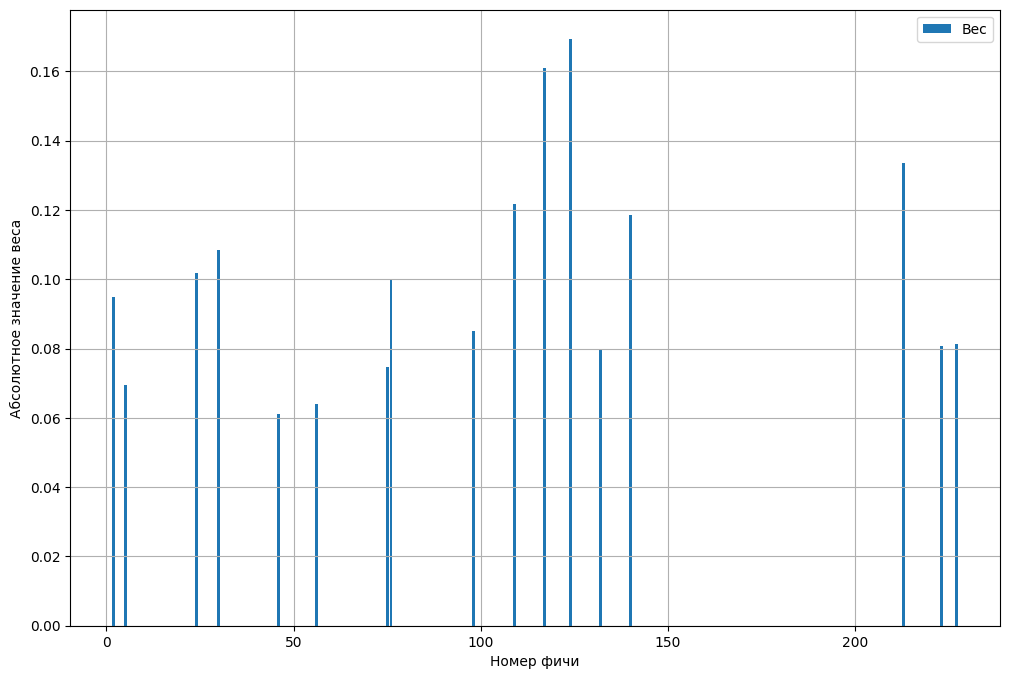

In [308]:
# your code here
weights = np.abs(logreg.coef_[0])
space = [int(f.split('_')[1]) for f in very_last_hope_features]
plt.figure(figsize=(12, 8))
plt.bar(space, weights, label = 'Вес')
plt.grid()
plt.xlabel("Номер фичи")
plt.ylabel("Абсолютное значение веса")
plt.legend()
plt.show()

In [309]:
space, weights

([140, 124, 5, 46, 213, 227, 117, 24, 76, 56, 98, 30, 132, 223, 75, 2, 109],
 array([0.11843566, 0.16931354, 0.06957086, 0.06100822, 0.13363335,
        0.08132103, 0.16100679, 0.10181758, 0.09980848, 0.06398973,
        0.08507906, 0.10830058, 0.07992532, 0.08059568, 0.07466367,
        0.09487824, 0.12179284]))

Мы помним, что по gain importance в районе 125 находилась очень важная фича. Сейчас мы знаем, что это 124 фича и что у неё наибольший вес в нашей модели, то есть её важность действительно была оправдана, а её догоняет 117 фича. Самый маленькие же веса у 46 и 56 признаков, их веса примерно одинаковые и примерно в 2.5 раза меньше веса 124 фичи.

# Бонусная часть (4 балла)

В разделе про бустинг мы обучали `LGBMClassifier` на довольно большом наборе фичей. Их количество можно сократить, при этом не теряя в качестве модели.

За начальный набор признаков можно взять все признаки (все 230) или признаки после отбора по IV.

**Ваша задача:** Отобрать признаки, подобрать оптимальные гиперпараметры и обучить `LGBMClassifier`.

Задание творческое) Можно использовать любые методы отбора признаков / оптимизации гиперпараметров.

**Чем меньше признаков, без ухудшения качества модели – тем лучше.**

Мы считаем, что изначально у нас 230 фичей, к которым мы применили фильтрующий метод отбора, то есть отсечение по IV, после этого осталось 63 фичи, к которым мы хотим применить что-то покруче типа обёрточных методов. То есть сейчас у нас бейзлайн из 63 оставшихся после фильтрации фичей, потом мы через оптюну подбираем параметры для бустинга на этих фичах и смотрим на метрику.

In [31]:
# your code here
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

features_optuna = iv_selected_features + iv_selected_cat_features
print(len(features_optuna))

train_data_df = df[df['sample_part'] == 'train']
valid_data_df = df[df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[features_optuna], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[features_optuna], label=valid_data_df[TARGET])

X_test = valid_data_df[features_optuna]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 52,
        'n_jobs' : -1,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
random_state_sampler = optuna.samplers.TPESampler(seed=52)
study = optuna.create_study(direction = 'maximize', sampler=random_state_sampler)
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

63


[I 2026-08-19 20:11:11,162] A new study created in memory with name: no-name-9fd67787-ecb8-4cac-9d48-daf945181a09


Training until validation scores don't improve for 10 rounds


[I 2026-08-19 20:11:13,467] Trial 0 finished with value: 0.6826847506070908 and parameters: {'num_leaves': 167, 'learning_rate': 0.0011606396616029259, 'feature_fraction': 0.6}. Best is trial 0 with value: 0.6826847506070908.


Early stopping, best iteration is:
[16]	valid_0's auc: 0.682685
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.677912


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.736481


[I 2026-08-19 20:15:35,027] Trial 48 finished with value: 0.7364814142787761 and parameters: {'num_leaves': 200, 'learning_rate': 0.05993015565101714, 'feature_fraction': 0.9}. Best is trial 43 with value: 0.7394172481787276.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.73752


[I 2026-08-19 20:15:43,288] Trial 49 finished with value: 0.7375195356969403 and parameters: {'num_leaves': 193, 'learning_rate': 0.12396317439865948, 'feature_fraction': 0.9}. Best is trial 43 with value: 0.7394172481787276.


Best params: {'num_leaves': 176, 'learning_rate': 0.08872004871077989, 'feature_fraction': 1.0}
Best AUC: 0.7394172481787276


In [32]:
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_bonus = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_bonus.predict(df[df['sample_part'] == 'test'][features_optuna])))

0.7232597543039099


Итак, теперь у нас есть бейзлайн: **0.7232597543039099 на 63 фичах**.

Начнём с самого простого - ещё одного фильтрующего метода, только на этот раз поиск сильно коррелирующих фичей. Мы знаем, что такие фичи - это плохо, потому что, во-первых, мы получаем несколько среднячковых фичей вместо одной сильной и важной, а во-вторых, никакой особой роли они не играют, качество они особо не увеличивают, в отличие от времени на обучение.

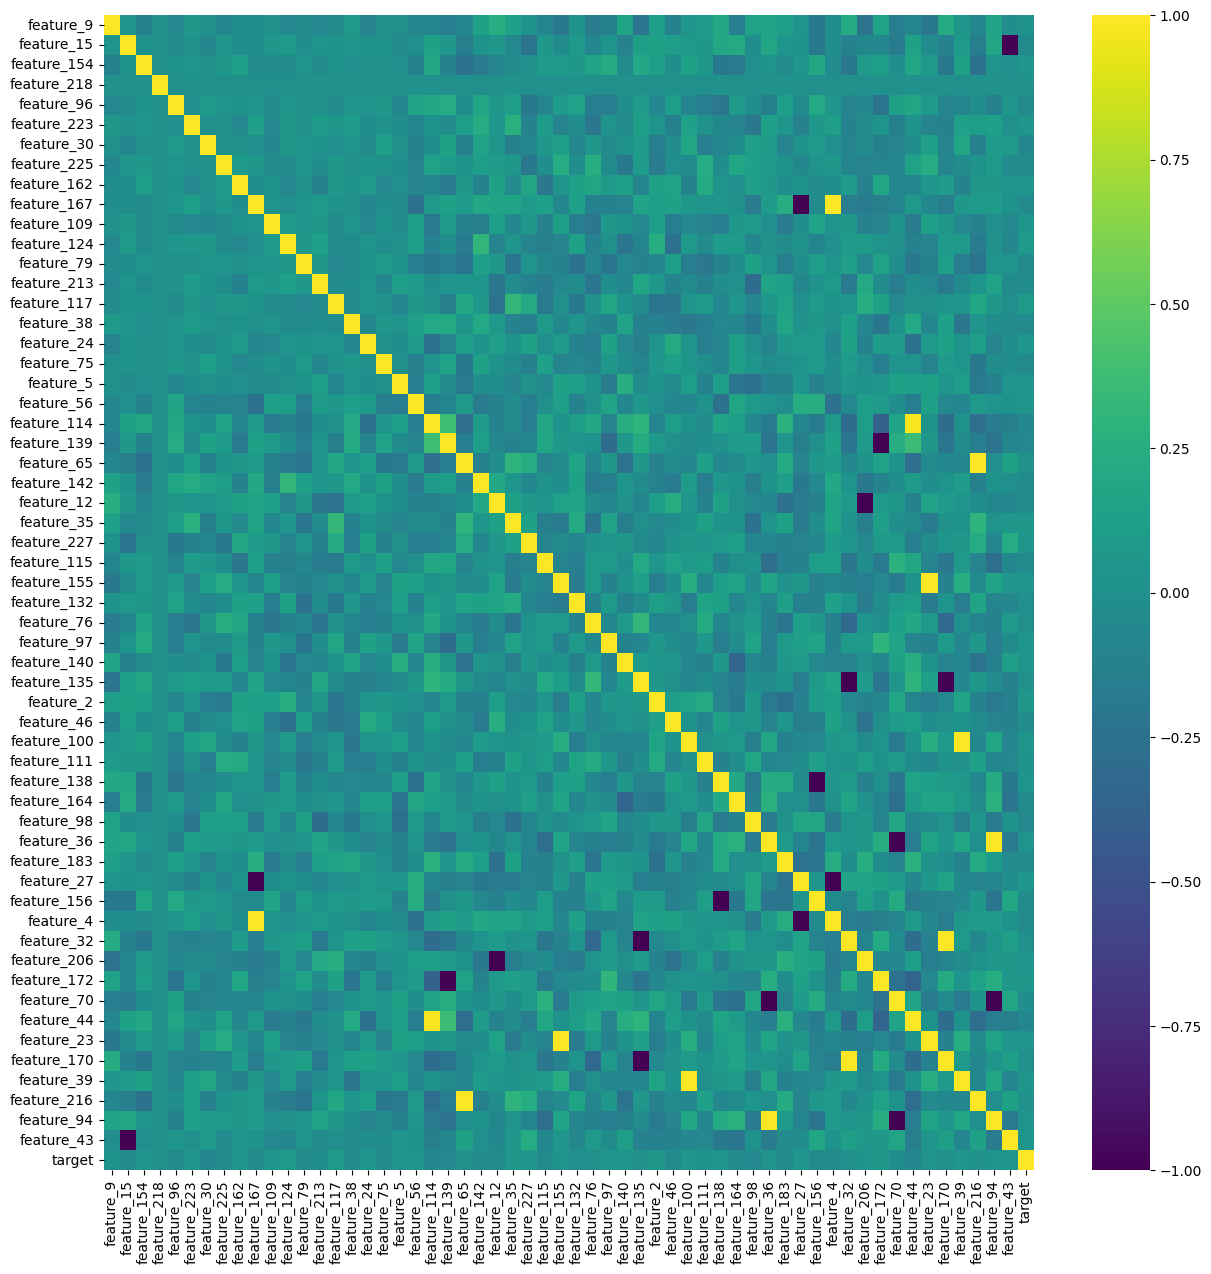

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

bonus_num_filtred_features = [f for f in df[features_optuna].select_dtypes(include = ['int64', 'float64']).columns if df[f].nunique() > 50 ]
bonus_cat_filtred_features = [f for f in features_optuna if f not in bonus_num_filtred_features]

plt.figure(figsize=(15, 15))
sns.heatmap(df[df['sample_part'] == 'train'][bonus_num_filtred_features + ['target']].corr(), cmap='viridis')
plt.show()

У нас появиось много кандидатов на устранение, так как мы видим кучу пар фичей, у которых корреляция либо единичная (например, 36 и 94 фича имеют единичную корреляцию), либо равна -1 (например, 70 и 94), а в нашем случае любая такая сильная корреляция никакой пользы не несёт. Попробуем максимально кардинальный отбор: отбросим в каждой паре сильно коррелирующих фичей одну, чтобы осталась одна сильная. Список таких фичей: (15, 167, 114, 139, 65, 12, 155, 135, 100, 138, 36, 27, 32, 70)

43


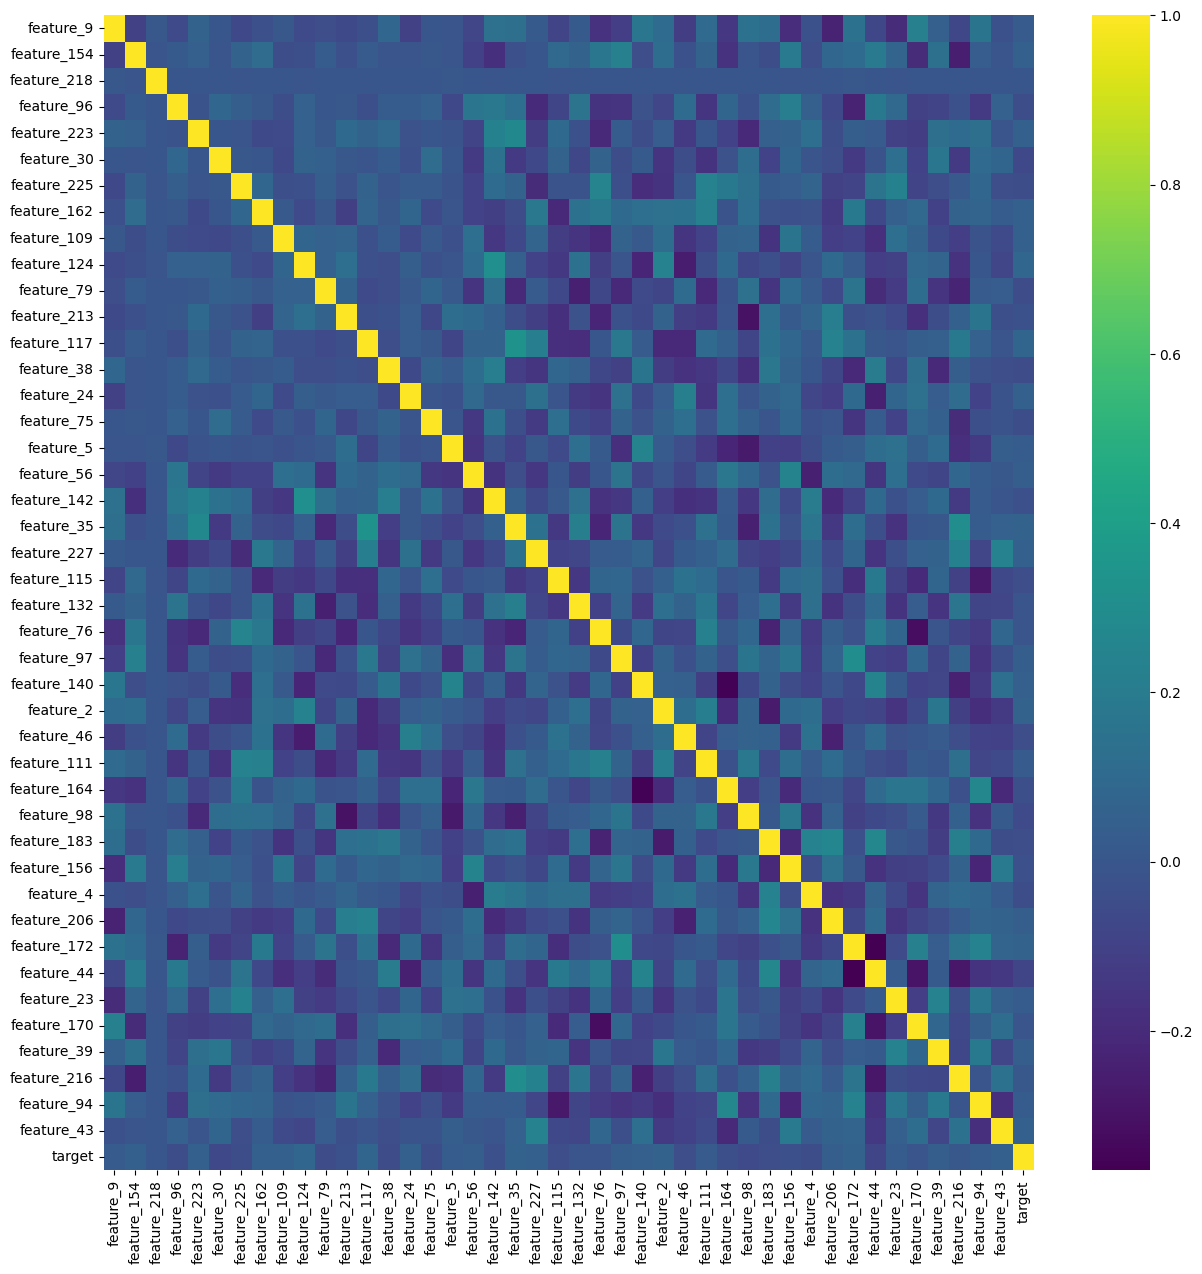

In [51]:
bonus_num_uncorr_features = [f for f in bonus_num_filtred_features if f not in ['feature_15', 'feature_167', 'feature_114', 'feature_139', 'feature_65', 'feature_12', 'feature_155', 'feature_135', 'feature_100', 'feature_138', 'feature_36', 'feature_27', 'feature_32', 'feature_70']]
print(len(bonus_num_uncorr_features))

plt.figure(figsize=(15, 15))
sns.heatmap(df[df['sample_part'] == 'train'][bonus_num_uncorr_features + ['target']].corr(), cmap='viridis')
plt.show()

Как мы видим, единичная корреляция теперь только у фичей с собой, а минимальная корреляция теперь не ниже -0.4, так что от сильно коррелирующих фичей мы избавились, пришло время подбирать гиперпараметры и обучать бустинг.

In [52]:
train_data_df = df[df['sample_part'] == 'train']
valid_data_df = df[df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[bonus_num_uncorr_features], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[bonus_num_uncorr_features], label=valid_data_df[TARGET])

X_test = valid_data_df[bonus_num_uncorr_features]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 52,
        'n_jobs' : -1,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
random_state_sampler = optuna.samplers.TPESampler(seed=52)
study = optuna.create_study(direction = 'maximize', sampler=random_state_sampler)
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 21:33:34,987] A new study created in memory with name: no-name-260f8496-395b-478f-bc6d-a9077c6eb7c6


Training until validation scores don't improve for 10 rounds


[I 2026-08-19 21:33:39,422] Trial 0 finished with value: 0.6872469145216125 and parameters: {'num_leaves': 167, 'learning_rate': 0.0011606396616029259, 'feature_fraction': 0.6}. Best is trial 0 with value: 0.6872469145216125.


Early stopping, best iteration is:
[79]	valid_0's auc: 0.687247
Training until validation scores don't improve for 10 rounds


[I 2026-08-19 21:33:43,643] Trial 1 finished with value: 0.6733000859640603 and parameters: {'num_leaves': 128, 'learning_rate': 0.0017517113264308903, 'feature_fraction': 0.8}. Best is trial 0 with value: 0.6872469145216125.


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.736065


[I 2026-08-19 21:37:12,705] Trial 48 finished with value: 0.7360650432248664 and parameters: {'num_leaves': 200, 'learning_rate': 0.09272958594527013, 'feature_fraction': 0.8}. Best is trial 23 with value: 0.737304306945119.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[99]	valid_0's auc: 0.681696


[I 2026-08-19 21:37:18,510] Trial 49 finished with value: 0.6816960534239922 and parameters: {'num_leaves': 159, 'learning_rate': 0.0032404756031741045, 'feature_fraction': 0.8}. Best is trial 23 with value: 0.737304306945119.


Best params: {'num_leaves': 185, 'learning_rate': 0.08000346195117028, 'feature_fraction': 0.9}
Best AUC: 0.737304306945119


In [53]:
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_bonus_v1 = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_bonus_v1.predict(df[df['sample_part'] == 'test'][bonus_num_uncorr_features])))

0.7276880871296806


Итак мы обновляем текущий результат: **0.7276880871296806 на 43 фичах** (потому что я забыл добавить категориальные, и бустинг обучался чисто на числовых признаках, но формально мы и метрику лучше получили, и фичей стало на 20 меньше: 14 сильно коррелирующих с присутствующими и 6 забытых категориальных :). Сейчас мы эту оплошность с категориальными исправим, сделав небольшие махинации с типами данных, но сначал скопируем весь датасет.

In [73]:
bonus_df = df[bonus_num_uncorr_features + bonus_cat_filtred_features + ['target', 'sample_part']].copy()
for f in bonus_cat_filtred_features:
    bonus_df[f] = bonus_df[f].astype('category').cat.codes.astype('category')

bonus_df[bonus_cat_filtred_features].info()

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 22620 to 310653
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype   
---  ------       --------------   -----   
 0   feature_147  500000 non-null  category
 1   feature_144  500000 non-null  category
 2   feature_168  500000 non-null  category
 3   feature_165  500000 non-null  category
 4   feature_31   500000 non-null  category
 5   feature_209  500000 non-null  category
dtypes: category(6)
memory usage: 6.7 MB


Следующий отбор будем производить уже обёрточным методом, а именно Recursive Feature Elimination, так как мы уже использовали целых два фильтрующих, то самое время хотя бы попробовать обёрточный.

In [85]:
bonus_train = bonus_df[bonus_df['sample_part'] == 'train']
bonus_test = bonus_df[bonus_df['sample_part'] == 'test']
bonus_val = bonus_df[bonus_df['sample_part'] == 'val']

In [92]:
from sklearn.feature_selection import RFE

model_bonus_v2 = lgb.LGBMClassifier(num_leaves=best_params['num_leaves'], 
                                    learning_rate=best_params['learning_rate'],
                                    feature_fraction=best_params['feature_fraction'],
                                    random_state=52,
                                    n_jobs=-1,
                                    importance_type='gain')

X_train_b = bonus_train[bonus_num_uncorr_features + bonus_cat_filtred_features]
y_train_b = bonus_train['target']

rfe = RFE(estimator=model_bonus_v2, n_features_to_select=40,verbose=1)

In [93]:
rfe.fit(X_train_b, y_train_b)

Fitting estimator with 49 features.
Fitting estimator with 48 features.
Fitting estimator with 47 features.
Fitting estimator with 46 features.
Fitting estimator with 45 features.
Fitting estimator with 44 features.
Fitting estimator with 43 features.
Fitting estimator with 42 features.
Fitting estimator with 41 features.


RFE(estimator=LGBMClassifier(feature_fraction=1.0, importance_type='gain',
                             learning_rate=0.08080039706895162, n_jobs=-1,
                             num_leaves=194, random_state=52),
    n_features_to_select=40, verbose=1)

In [94]:
rfe.ranking_

array([ 1,  1, 10,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  3,  1,  1,  2,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  9,  5,  6,  8,  7,  4])

In [95]:
bonus_30_features = [f for f, r in zip(bonus_num_uncorr_features + bonus_cat_filtred_features, rfe.ranking_) if r == 1]
bonus_30_features, len(bonus_30_features)

(['feature_9',
  'feature_154',
  'feature_96',
  'feature_223',
  'feature_30',
  'feature_225',
  'feature_162',
  'feature_109',
  'feature_124',
  'feature_79',
  'feature_213',
  'feature_117',
  'feature_38',
  'feature_24',
  'feature_75',
  'feature_5',
  'feature_56',
  'feature_35',
  'feature_227',
  'feature_132',
  'feature_76',
  'feature_97',
  'feature_140',
  'feature_2',
  'feature_46',
  'feature_111',
  'feature_164',
  'feature_98',
  'feature_183',
  'feature_156',
  'feature_4',
  'feature_206',
  'feature_172',
  'feature_44',
  'feature_23',
  'feature_170',
  'feature_39',
  'feature_216',
  'feature_94',
  'feature_43'],
 40)

In [96]:
train_data_df = bonus_df[bonus_df['sample_part'] == 'train']
valid_data_df = bonus_df[bonus_df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[bonus_30_features], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[bonus_30_features], label=valid_data_df[TARGET])

X_test = valid_data_df[bonus_30_features]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 52,
        'n_jobs' : -1,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
random_state_sampler = optuna.samplers.TPESampler(seed=52)
study = optuna.create_study(direction = 'maximize', sampler=random_state_sampler)
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 23:01:57,771] A new study created in memory with name: no-name-caa4cea2-9b25-46b0-b817-6e5292f58a14


Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[70]	valid_0's auc: 0.687231


[I 2026-08-19 23:02:04,113] Trial 0 finished with value: 0.6872314686741137 and parameters: {'num_leaves': 167, 'learning_rate': 0.0011606396616029259, 'feature_fraction': 0.6}. Best is trial 0 with value: 0.6872314686741137.


Training until validation scores don't improve for 10 rounds


[I 2026-08-19 23:02:06,433] Trial 1 finished with value: 0.6681948533268577 and parameters: {'num_leaves': 128, 'learning_rate': 0.0017517113264308903, 'feature_fraction': 0.8}. Best is trial 0 with value: 0.6872314686741137.


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.732891


[I 2026-08-19 23:08:27,698] Trial 48 finished with value: 0.7328912467217096 and parameters: {'num_leaves': 173, 'learning_rate': 0.0982041925250107, 'feature_fraction': 1.0}. Best is trial 41 with value: 0.7350480228266149.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.712113


[I 2026-08-19 23:08:42,387] Trial 49 finished with value: 0.7121132088392423 and parameters: {'num_leaves': 190, 'learning_rate': 0.023195515845355768, 'feature_fraction': 0.9}. Best is trial 41 with value: 0.7350480228266149.


Best params: {'num_leaves': 184, 'learning_rate': 0.08173916453992107, 'feature_fraction': 1.0}
Best AUC: 0.7350480228266149


In [97]:
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_bonus_v3 = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_bonus_v3.predict(df[df['sample_part'] == 'test'][bonus_30_features])))

0.7261795118220213


Мы ещё в игре! Теперь наш рекорд: **0.7261795118220213 на 40 фичах.** Итак, мы попробовали два фильтрующих метода, один обёрточный метод, теперь попробуем нечто другое - отбор по шапам.

In [98]:
import shap

explainer = shap.TreeExplainer(model_bonus_v3)
X_test = df[df['sample_part'] == 'test'][bonus_30_features]
shap_values = explainer.shap_values(X_test)


c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


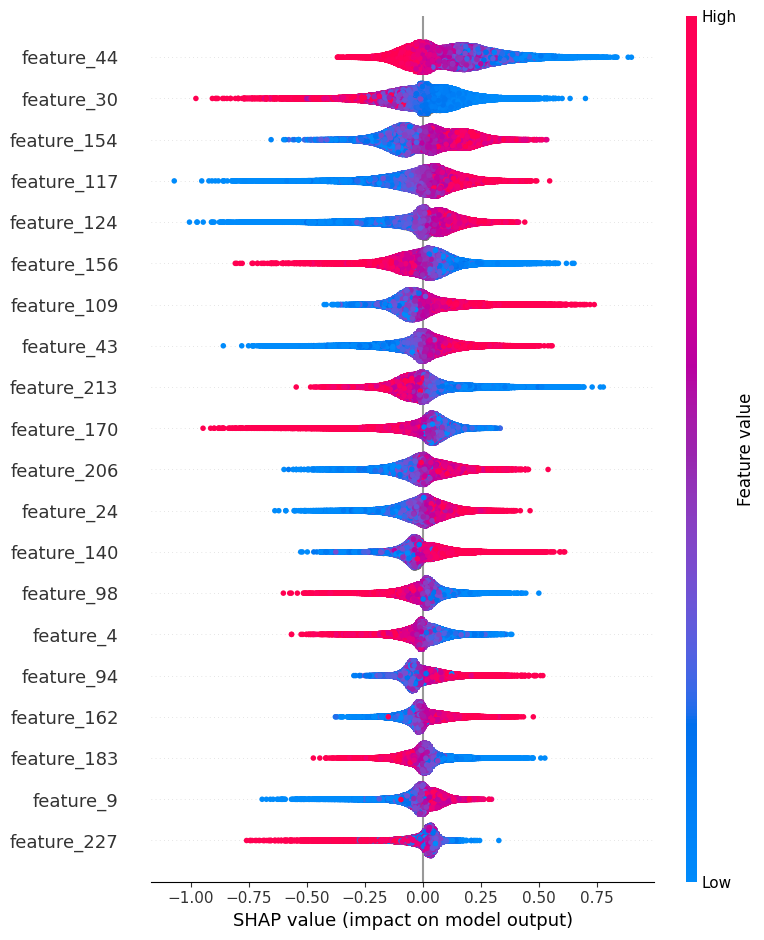

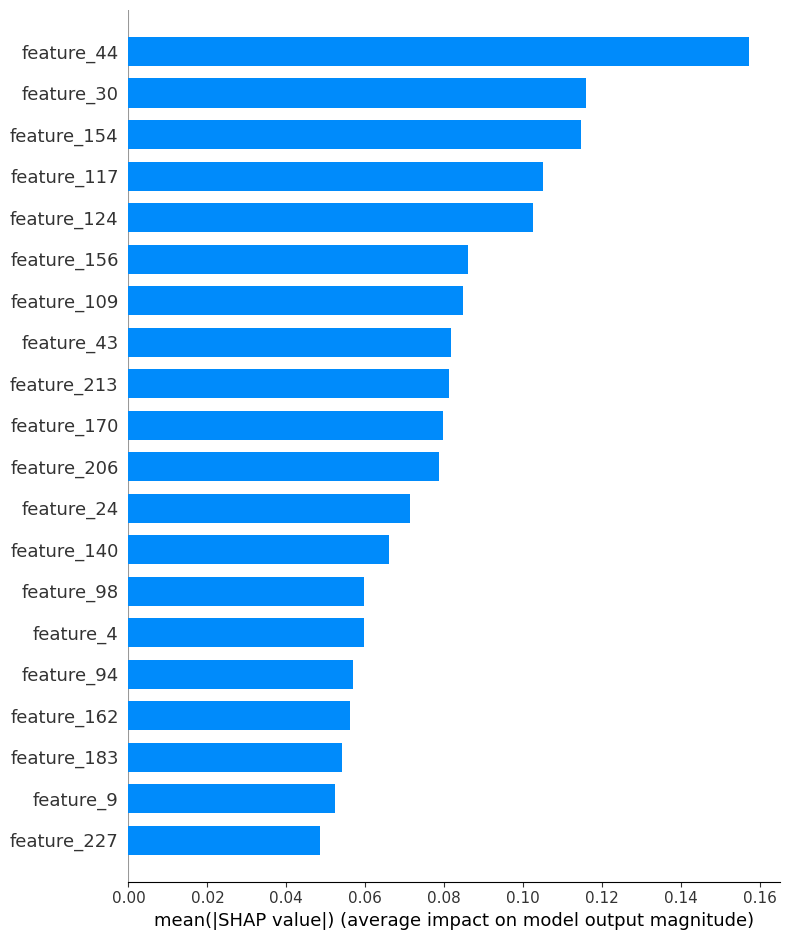

In [99]:
shap.summary_plot(shap_values, X_test, feature_names=bonus_30_features, show = True)

shap.summary_plot(shap_values, X_test, feature_names=bonus_30_features, show = True, plot_type='bar')

Отсюда видно, что все наши фичи +- информативны, но, кажется, можно откинуть ещё одну или две фичи снизу,что мы и попробуем сделать.

In [101]:
finale_features = [f for f in bonus_30_features if f not in ['feature_9', 'feature_227']]
len(finale_features), finale_features

(38,
 ['feature_154',
  'feature_96',
  'feature_223',
  'feature_30',
  'feature_225',
  'feature_162',
  'feature_109',
  'feature_124',
  'feature_79',
  'feature_213',
  'feature_117',
  'feature_38',
  'feature_24',
  'feature_75',
  'feature_5',
  'feature_56',
  'feature_35',
  'feature_132',
  'feature_76',
  'feature_97',
  'feature_140',
  'feature_2',
  'feature_46',
  'feature_111',
  'feature_164',
  'feature_98',
  'feature_183',
  'feature_156',
  'feature_4',
  'feature_206',
  'feature_172',
  'feature_44',
  'feature_23',
  'feature_170',
  'feature_39',
  'feature_216',
  'feature_94',
  'feature_43'])

In [102]:
train_data_df = bonus_df[bonus_df['sample_part'] == 'train']
valid_data_df = bonus_df[bonus_df['sample_part'] == 'val']
train_data = lgb.Dataset(train_data_df[finale_features], label=train_data_df[TARGET])
valid_data = lgb.Dataset(valid_data_df[finale_features], label=valid_data_df[TARGET])

X_test = valid_data_df[finale_features]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 52,
        'n_jobs' : -1,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1, step=0.1), # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=10)])
    auc = roc_auc_score(valid_data_df[TARGET], model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
random_state_sampler = optuna.samplers.TPESampler(seed=52)
study = optuna.create_study(direction = 'maximize', sampler=random_state_sampler)
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 23:27:55,055] A new study created in memory with name: no-name-4898b44a-2236-4b1e-ad30-da33277427d8


Training until validation scores don't improve for 10 rounds


[I 2026-08-19 23:28:00,463] Trial 0 finished with value: 0.6859647610490529 and parameters: {'num_leaves': 167, 'learning_rate': 0.0011606396616029259, 'feature_fraction': 0.6}. Best is trial 0 with value: 0.6859647610490529.


Early stopping, best iteration is:
[38]	valid_0's auc: 0.685965
Training until validation scores don't improve for 10 rounds


[I 2026-08-19 23:28:05,271] Trial 1 finished with value: 0.6661336520155415 and parameters: {'num_leaves': 128, 'learning_rate': 0.0017517113264308903, 'feature_fraction': 0.8}. Best is trial 0 with value: 0.6859647610490529.


...

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[94]	valid_0's auc: 0.729535


[I 2026-08-19 23:33:57,913] Trial 48 finished with value: 0.7295348936376881 and parameters: {'num_leaves': 186, 'learning_rate': 0.09589094953919071, 'feature_fraction': 0.6}. Best is trial 32 with value: 0.7310193370568238.


Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.728051


[I 2026-08-19 23:34:08,743] Trial 49 finished with value: 0.728051401651287 and parameters: {'num_leaves': 160, 'learning_rate': 0.07443267056723284, 'feature_fraction': 0.7}. Best is trial 32 with value: 0.7310193370568238.


Best params: {'num_leaves': 192, 'learning_rate': 0.0747400318279718, 'feature_fraction': 0.9}
Best AUC: 0.7310193370568238


In [103]:
best_params = study.best_params
best_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'random_state': 52,
        'boosting_type': 'gbdt',
        'n_jobs' : -1
        })

model_bonus_v4 = lgb.train(params=best_params, train_set=train_data)
print(roc_auc_score(df[df['sample_part'] == 'test'][TARGET], model_bonus_v4.predict(df[df['sample_part'] == 'test'][finale_features])))

0.7213551544494362


Как мы видим, мы получили **0.7213551544494362 на 38 фичах**, что совсем немного меньше нашего бейзлайна, а именно на $\approx 0.002$, что можно считать приемлемым, учитывая, что бейзлайн был на 63 фичах.

Идеи для отбора признаков:

- Воспользоваться методами из модуля `sklearn.feature_selection` (точно можно попробовать RFE). Документация https://scikit-learn.org/stable/modules/feature_selection.html
<!-- - С помощью `BorutaPy` из библиотеки `boruta` (https://towardsdatascience.com/simple-example-using-boruta-feature-selection-in-python-8b96925d5d7a – статья может помочь разобраться с запуском алгоритма (мб не откроется без vpn)) -->
- permutation importance и elimination по нему (https://scikit-learn.org/stable/modules/permutation_importance.html)
- попробовать использовать shap-values